# Q-learning with a Continuous State: CartPole
FrozenLake has 16 discrete states, so a Q-table fits directly. CartPole's state is **4 continuous numbers**
(cart position, cart velocity, pole angle, pole angular velocity), so `env.observation_space` is a `Box` with no `.n` -
a Q-table cannot index it directly.

The simplest fix is to **discretize**: chop each variable into bins and use the bin indices as the table index.
(Deep RL methods such as DQN replace the table with a neural network instead.)

Each step the pole stays up earns reward 1; the episode is truncated at 500 steps. CartPole-v1 counts as "solved" at an average of 475.

In [1]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
env = gym.make('CartPole-v1')
print(env.observation_space)
print(env.action_space)

Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Discrete(2)


In [2]:
class DiscretizedQLearningAgent:
    def __init__(self, bins, action_space, learning_rate=0.1, discount_factor=0.99,
                 exploration_rate=1.0, exploration_decay=0.999, min_exploration=0.01):
        self.bins = bins  # one array of bin edges per state variable
        self.action_space = action_space
        self.learning_rate = learning_rate
        self.discount_factor = discount_factor
        self.exploration_rate = exploration_rate
        self.exploration_decay = exploration_decay
        self.min_exploration = min_exploration
        self.q_table = np.zeros([len(b) + 1 for b in bins] + [action_space])

    def discretize(self, observation):
        return tuple(int(np.digitize(x, b)) for x, b in zip(observation, self.bins))

    def choose_action(self, state, greedy=False):
        if not greedy and rng.random() < self.exploration_rate:
            return int(rng.integers(self.action_space))
        return int(np.argmax(self.q_table[state]))

    def update_q_table(self, state, action, reward, next_state, terminated):
        future = 0.0 if terminated else np.max(self.q_table[next_state])
        td_target = reward + self.discount_factor * future
        td_error = td_target - self.q_table[state][action]
        self.q_table[state][action] += self.learning_rate * td_error

    def decay_exploration(self):
        self.exploration_rate = max(self.min_exploration, self.exploration_rate * self.exploration_decay)

# Bin edges: position and velocity matter less than the pole angle and its rate of change
bins = [np.linspace(-2.4, 2.4, 3),
        np.linspace(-3.0, 3.0, 3),
        np.linspace(-0.21, 0.21, 7),
        np.linspace(-3.0, 3.0, 7)]
agent = DiscretizedQLearningAgent(bins, env.action_space.n)
print(f"Q-table shape: {agent.q_table.shape} = {agent.q_table.size} entries")

Q-table shape: (4, 4, 8, 8, 2) = 2048 entries


In [3]:
num_episodes = 5000
episode_rewards = []
best_avg, best_q_table = -np.inf, None

for episode in range(num_episodes):
    obs, _ = env.reset(seed=episode)
    state = agent.discretize(obs)
    total_reward = 0
    done = False
    while not done:
        action = agent.choose_action(state)
        obs, reward, terminated, truncated, _ = env.step(action)
        next_state = agent.discretize(obs)
        agent.update_q_table(state, action, reward, next_state, terminated)
        state = next_state
        total_reward += reward
        done = terminated or truncated
    agent.decay_exploration()
    episode_rewards.append(total_reward)

    # Checkpoint the policy whenever the rolling average hits a new best
    rolling_avg = np.mean(episode_rewards[-100:])
    if episode >= 100 and rolling_avg >= best_avg:
        best_avg, best_q_table = rolling_avg, agent.q_table.copy()
    if (episode + 1) % 1000 == 0:
        print(f"Episode {episode + 1}: average reward (last 1000) = {np.mean(episode_rewards[-1000:]):.1f}, "
              f"exploration = {agent.exploration_rate:.3f}")

print(f"Last 100 episodes: {np.mean(episode_rewards[-100:]):.1f}, best rolling average: {best_avg:.1f}")

Episode 1000: average reward (last 1000) = 58.1, exploration = 0.368


Episode 2000: average reward (last 1000) = 304.4, exploration = 0.135


Episode 3000: average reward (last 1000) = 394.5, exploration = 0.050


Episode 4000: average reward (last 1000) = 422.2, exploration = 0.018


Episode 5000: average reward (last 1000) = 446.8, exploration = 0.010
Last 100 episodes: 200.2, best rolling average: 500.0


## Keep the best policy, not the last one
Tabular Q-learning on CartPole is unstable: a good policy can suddenly degrade as updates continue
(look for drops at the end of the learning curve). Like early stopping in supervised learning, we keep the
best checkpoint seen during training and evaluate that.

In [4]:
final_q_table = agent.q_table
agent.q_table = best_q_table

Best checkpoint - Average Reward: 500.0 (+/- 0.0)
Final Q-table   - Average Reward: 96.2
Success Rate (balanced all 500 steps): 100%
Visited Q-table states: 13%


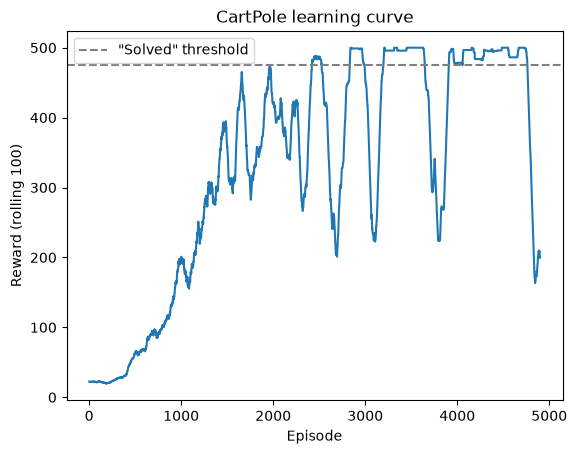

In [5]:
# Greedy evaluation of the learned policy
max_steps = env.spec.max_episode_steps
def greedy_reward(q_table, seed):
    obs, _ = env.reset(seed=seed)
    total_reward, done = 0, False
    while not done:
        action = int(np.argmax(q_table[agent.discretize(obs)]))
        obs, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        done = terminated or truncated
    return total_reward

eval_rewards = np.array([greedy_reward(agent.q_table, 100_000 + i) for i in range(100)])
final_avg = np.mean([greedy_reward(final_q_table, 100_000 + i) for i in range(100)])
print(f"Best checkpoint - Average Reward: {eval_rewards.mean():.1f} (+/- {eval_rewards.std():.1f})")
print(f"Final Q-table   - Average Reward: {final_avg:.1f}")
print(f"Success Rate (balanced all {max_steps} steps): {(eval_rewards >= max_steps).mean():.0%}")
print(f"Visited Q-table states: {(np.abs(agent.q_table).sum(axis=-1) > 0).mean():.0%}")

plt.plot(np.convolve(episode_rewards, np.ones(100) / 100, mode='valid'))
plt.axhline(475, color='gray', linestyle='--', label='"Solved" threshold')
plt.xlabel('Episode')
plt.ylabel('Reward (rolling 100)')
plt.title('CartPole learning curve')
plt.legend()
plt.show()
env.close()

**Takeaway:** discretization works but scales badly - the table grows as (bins per variable)^(number of variables),
and coarse bins limit how good the policy can get. That trade-off between table size and policy quality is
what motivates function approximation (DQN, policy-gradient methods).